# Bidirectional Image–Text Retrieval

**Project 2.2 | implementation**

COCO 2017 image–caption retrieval using three methods: InfoNCE, hard-negative triplet ranking, and early-fusion MLP. All methods share image-disjoint splits and frozen ResNet-50/BERT features.

## 1. Data and pretrained features

Clean captions, split 4,000/500/500 images, then cache image and text embeddings. No test results are used during model selection.

In [1]:
import importlib.util
import subprocess
import sys

for module, package in [
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("datasets", "datasets"),
    ("transformers", "transformers"),
    ("PIL", "Pillow"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
]:
    if importlib.util.find_spec(module) is None:
        print(f"Installing missing package: {package}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

from pathlib import Path
from collections import Counter, defaultdict
from zipfile import ZipFile, ZIP_STORED, ZIP_DEFLATED
import json, random, hashlib, time, gc, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset, Image
from torchvision.models import resnet50, ResNet50_Weights
from transformers import AutoTokenizer, AutoModel

PROJECT = Path.cwd() / "multimodal_project"
DATA = PROJECT / "shared_data"
MODELS = PROJECT / "models"
RESULTS = PROJECT / "results"
for directory in (DATA, MODELS, RESULTS):
    directory.mkdir(parents=True, exist_ok=True)

DATASET = "lmms-lab/COCO-Caption2017"
DATA_SPLIT = "val"
SPLIT_SEED = 42
RUN_SEEDS = [42, 43, 44]            # Three reproducibility runs as promised in proposal
TRAIN_N, VAL_N, TEST_N = 4000, 500, 500
EMBED_DIM, BATCH_SIZE = 256, 128
LR, WEIGHT_DECAY, TEMP = 1e-3, 0.01, 0.07
MAX_EPOCHS, PATIENCE = 30, 7
MAX_TOKENS, IMAGE_BATCH, TEXT_BATCH = 64, 16, 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


print("Device:", DEVICE)
print("Dataset splits:", TRAIN_N, VAL_N, TEST_N)
print("Random seeds:", RUN_SEEDS)

Device: cuda
Dataset splits: 4000 500 500
Random seeds: [42, 43, 44]


In [2]:
placeholder = "there is no image here to provide a caption for."
stream = load_dataset(DATASET, split=DATA_SPLIT, streaming=True)
stream = stream.cast_column("image", Image(decode=False))
records, removed_examples = [], []

for row in stream:
    cleaned = []
    for caption in (row["answer"] or []):
        if not isinstance(caption, str) or not caption.strip() or caption.strip().casefold() == placeholder:
            removed_examples.append({"image_id": int(row["id"]), "caption": str(caption)})
        else:
            cleaned.append(caption.strip())
    records.append({
        "id": int(row["id"]),
        "file_name": str(row["file_name"]),
        "width": int(row["width"]),
        "height": int(row["height"]),
        "license": str(row["license"]),
        "captions": cleaned
    })

assert len(records) == 5000, f"Unexpected dataset size: {len(records)}"
assert len({r["id"] for r in records}) == 5000, "Duplicate image IDs"
assert all(r["captions"] for r in records), "An image lost all valid captions"

all_captions = [c for r in records for c in r["captions"]]
caption_owners = defaultdict(set)
for r in records:
    for c in r["captions"]:
        caption_owners[c.strip().casefold()].add(r["id"])

cross_image_duplicates = {c: sorted(ids) for c, ids in caption_owners.items() if len(ids) > 1}
lengths = [len(c.split()) for c in all_captions]
audit = {
    "dataset": DATASET,
    "source_split": DATA_SPLIT,
    "image_count": len(records),
    "valid_caption_count": len(all_captions),
    "removed_captions": removed_examples,
    "mean_words_per_caption": float(np.mean(lengths)),
    "median_words_per_caption": float(np.median(lengths)),
    "caption_counts_per_image": dict(Counter(str(len(r["captions"])) for r in records)),
    "duplicate_caption_occurrences": len(all_captions) - len(set(all_captions)),
    "cross_image_duplicate_texts": len(cross_image_duplicates),
    "sample_cross_image_duplicates": dict(list(cross_image_duplicates.items())[:8]),
    "width_min_max": [min(r["width"] for r in records), max(r["width"] for r in records)],
    "height_min_max": [min(r["height"] for r in records), max(r["height"] for r in records)],
    "license_code_counts": dict(Counter(r["license"] for r in records)),
    "notes": "Image licences are not all the same; verify licences before publishing any images."
}

shuffled = records.copy()
random.Random(SPLIT_SEED).shuffle(shuffled)
splits = {
    "train": shuffled[:TRAIN_N],
    "validation": shuffled[TRAIN_N:TRAIN_N+VAL_N],
    "test": shuffled[TRAIN_N+VAL_N:]
}
assert [len(splits[k]) for k in ("train", "validation", "test")] == [4000, 500, 500]
ids_by_split = {k: {r["id"] for r in v} for k, v in splits.items()}
assert ids_by_split["train"].isdisjoint(ids_by_split["validation"])
assert ids_by_split["train"].isdisjoint(ids_by_split["test"])
assert ids_by_split["validation"].isdisjoint(ids_by_split["test"])

with (DATA / "coco_splits.json").open("w", encoding="utf-8") as f:
    json.dump(splits, f, indent=2, ensure_ascii=False)
with (RESULTS / "dataset_audit.json").open("w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)


print("Images:", audit["image_count"])
print("Valid captions:", audit["valid_caption_count"])
print("Invalid captions removed:", len(removed_examples))
print("Mean caption length:", round(audit["mean_words_per_caption"], 2))
print("Repeated captions across images:", audit["cross_image_duplicate_texts"])

for name, rows in splits.items():
    print(f"{name}: {len(rows)} images")

README.md:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

Images: 5000
Valid captions: 25010
Invalid captions removed: 4
Mean caption length: 10.44
Repeated captions across images: 121
train: 4000 images
validation: 500 images
test: 500 images


In [3]:
weights = ResNet50_Weights.DEFAULT
image_transform = weights.transforms()
image_encoder = resnet50(weights=weights)
image_encoder.fc = nn.Identity()
image_encoder = image_encoder.to(DEVICE).eval()

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
text_encoder = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()

for encoder in (image_encoder, text_encoder):
    for parameter in encoder.parameters():
        parameter.requires_grad_(False)

print("ResNet-50: 2048-D", "| BERT: 768-D", "| frozen encoders ready")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ResNet-50: 2048-D | BERT: 768-D | frozen encoders ready


In [4]:
all_records = splits["train"] + splits["validation"] + splits["test"]
image_ids = [r["id"] for r in all_records]
image_index = {image_id: pos for pos, image_id in enumerate(image_ids)}
assert len(image_index) == 5000

image_feature_path = DATA / "image_features.pt"
start = time.perf_counter()
if image_feature_path.exists():
    print("Image cache already exists; checking it instead of recomputing.")
    image_package = torch.load(image_feature_path, map_location="cpu", weights_only=True)
    assert image_package["image_ids"] == image_ids
    assert image_package["features"].shape == (5000, 2048)
else:
    image_features = torch.empty((5000, 2048), dtype=torch.float32)
    seen = set()
    queued_images, queued_indices = [], []

    def flush_images():
        if not queued_images:
            return
        batch = torch.stack(queued_images).to(DEVICE)
        with torch.inference_mode():
            values = image_encoder(batch).float().cpu()
        image_features[queued_indices] = values
        queued_images.clear()
        queued_indices.clear()

    image_stream = load_dataset(DATASET, split=DATA_SPLIT, streaming=True)
    for row in image_stream:
        image_id = int(row["id"])
        if image_id not in image_index:
            continue
        assert image_id not in seen, f"Duplicate ID in streamed images: {image_id}"
        seen.add(image_id)
        queued_images.append(image_transform(row["image"].convert("RGB")))
        queued_indices.append(image_index[image_id])
        if len(queued_images) >= IMAGE_BATCH:
            flush_images()
        if len(seen) % 500 == 0:
            print("Images processed:", len(seen), "/ 5000")
    flush_images()
    assert len(seen) == 5000
    assert torch.isfinite(image_features).all()
    torch.save({
        "features": image_features,
        "image_ids": image_ids,
        "encoder": "ResNet50_Weights.DEFAULT",
        "dimensions": 2048,
    }, image_feature_path)
    del image_features
    image_package = torch.load(image_feature_path, map_location="cpu", weights_only=True)

print("Image features:", tuple(image_package["features"].shape))
print("Saved:", image_feature_path, "| elapsed:", round(time.perf_counter()-start, 2), "seconds")

Images processed: 500 / 5000
Images processed: 1000 / 5000
Images processed: 1500 / 5000
Images processed: 2000 / 5000
Images processed: 2500 / 5000
Images processed: 3000 / 5000
Images processed: 3500 / 5000
Images processed: 4000 / 5000
Images processed: 4500 / 5000
Images processed: 5000 / 5000
Image features: (5000, 2048)
Saved: /content/multimodal_project/shared_data/image_features.pt | elapsed: 71.92 seconds


In [5]:
text_feature_path = DATA / "text_features.pt"
all_captions, caption_image_indices, caption_splits = [], [], []
for split_name, start_idx, rows in [
    ("train", 0, splits["train"]),
    ("validation", TRAIN_N, splits["validation"]),
    ("test", TRAIN_N + VAL_N, splits["test"]),
]:
    for local_idx, row in enumerate(rows):
        for caption in row["captions"]:
            all_captions.append(caption)
            caption_image_indices.append(start_idx + local_idx)
            caption_splits.append(split_name)

start = time.perf_counter()
if text_feature_path.exists():
    print("Text cache already exists; checking it instead of recomputing.")
    text_package = torch.load(text_feature_path, map_location="cpu", weights_only=True)
    assert text_package["captions"] == all_captions
    assert text_package["caption_image_indices"] == caption_image_indices
    assert text_package["features"].shape == (len(all_captions), 768)
else:
    text_parts = []
    for pos in range(0, len(all_captions), TEXT_BATCH):
        batch_texts = all_captions[pos:pos+TEXT_BATCH]
        token_batch = tokenizer(
            batch_texts, padding=True, truncation=True,
            max_length=MAX_TOKENS, return_tensors="pt"
        ).to(DEVICE)
        with torch.inference_mode():
            states = text_encoder(**token_batch).last_hidden_state
            mask = token_batch["attention_mask"].unsqueeze(-1)
            pooled = (states * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
            text_parts.append(pooled.float().cpu())
        if pos and (pos // TEXT_BATCH) % 40 == 0:
            print("Captions processed:", pos, "/", len(all_captions))
    text_features = torch.cat(text_parts)
    assert torch.isfinite(text_features).all()
    torch.save({
        "features": text_features,
        "captions": all_captions,
        "caption_image_indices": caption_image_indices,
        "caption_splits": caption_splits,
        "encoder": "bert-base-uncased",
        "pooling": "masked_mean",
        "max_length": MAX_TOKENS,
    }, text_feature_path)
    del text_features, text_parts
    text_package = torch.load(text_feature_path, map_location="cpu", weights_only=True)

assert len(all_captions) == sum(len(r["captions"]) for r in all_records)
print("Caption features:", tuple(text_package["features"].shape))
print("Saved:", text_feature_path, "| elapsed:", round(time.perf_counter()-start, 2), "seconds")

Captions processed: 2560 / 25010
Captions processed: 5120 / 25010
Captions processed: 7680 / 25010
Captions processed: 10240 / 25010
Captions processed: 12800 / 25010
Captions processed: 15360 / 25010
Captions processed: 17920 / 25010
Captions processed: 20480 / 25010
Captions processed: 23040 / 25010
Caption features: (25010, 768)
Saved: /content/multimodal_project/shared_data/text_features.pt | elapsed: 38.47 seconds


In [6]:
images = torch.load(image_feature_path, map_location="cpu", weights_only=True)
texts = torch.load(text_feature_path, map_location="cpu", weights_only=True)
assert images["image_ids"] == image_ids
assert texts["captions"] == all_captions
assert texts["caption_image_indices"] == caption_image_indices
assert images["features"].shape == (5000, 2048)
assert texts["features"].shape == (len(all_captions), 768)
assert min(caption_image_indices) == 0 and max(caption_image_indices) == 4999
assert all(caption_splits[j] == ("train" if i < 4000 else "validation" if i < 4500 else "test")
           for j, i in enumerate(caption_image_indices))

shared_zip = PROJECT / "multimodal_shared_data.zip"
with ZipFile(shared_zip, "w", ZIP_STORED) as z:
    for p in [DATA / "coco_splits.json", image_feature_path, text_feature_path, RESULTS / "dataset_audit.json"]:
        z.write(p, arcname=str(p.relative_to(PROJECT)))

print("Shared package:", shared_zip)
print("Size (MB):", round(shared_zip.stat().st_size / 1024**2, 2))

Shared package: /content/multimodal_project/multimodal_shared_data.zip
Size (MB): 116.34


## 2. InfoNCE contrastive baseline

Train 256-D image or text projections with symmetric InfoNCE over three seeds, choose checkpoints by validation Recall@1

In [7]:
# Once cached, release encoder GPU memory. We train only projections below.
del image_encoder, text_encoder
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

X_img = images["features"].float().to(DEVICE)
X_txt = texts["features"].float().to(DEVICE)
caption_to_image = torch.tensor(texts["caption_image_indices"], dtype=torch.long, device=DEVICE)
caption_keys = [str(c).strip().casefold() for c in texts["captions"]]
unique_keys = {key: i for i, key in enumerate(dict.fromkeys(caption_keys))}
key_ids = torch.tensor([unique_keys[k] for k in caption_keys], dtype=torch.long, device=DEVICE)
image_to_caption = [[] for _ in range(5000)]
for ci, img_i in enumerate(texts["caption_image_indices"]):
    image_to_caption[img_i].append(ci)
assert all(image_to_caption[i] for i in range(5000))

train_ids = list(range(4000))
val_ids = torch.arange(4000, 4500, device=DEVICE)
val_caption_ids = torch.where((caption_to_image >= 4000) & (caption_to_image < 4500))[0]

class InfoNCEModel(nn.Module):
    def __init__(self, dimension=EMBED_DIM):
        super().__init__()
        self.image_projection = nn.Linear(2048, dimension)
        self.text_projection = nn.Linear(768, dimension)

    def forward(self, x_image, x_text):
        return (F.normalize(self.image_projection(x_image), dim=-1),
                F.normalize(self.text_projection(x_text), dim=-1))


def recall_mrr(similarity, correct):
    """True if ANY valid caption/image occurs in top-k; returns R@k and MRR."""
    order = similarity.argsort(dim=1, descending=True)
    hits = correct.gather(1, order)
    assert hits.any(dim=1).all(), "Some retrieval queries have no eligible correct result"
    first = hits.to(torch.int32).argmax(dim=1) + 1
    return {f"R@{k}": float((first <= k).float().mean()) for k in (1, 5, 10)} | {
        "MRR": float((1.0 / first.float()).mean())
    }


def retrieval_metrics(model, gallery_images, gallery_captions, include_strict=False):
    """Unified retrieval protocol; gallery uses all legitimate captions."""
    model.eval()
    with torch.inference_mode():
        a = F.normalize(model.image_projection(X_img[gallery_images]), dim=-1)
        b = F.normalize(model.text_projection(X_txt[gallery_captions]), dim=-1)
        similarities = a @ b.T
        truth = gallery_images[:, None].eq(caption_to_image[gallery_captions][None, :])
        strict = {
            "image_to_text": recall_mrr(similarities, truth),
            "text_to_image": recall_mrr(similarities.T, truth.T),
        }
        # Identical text belonging to distinct gallery images is ambiguous.
        # Accept any of those gallery images (both retrieval directions).
        ambiguous = truth.clone()
        owner_by_key = defaultdict(set)
        for image_i, cap_i in zip(
            caption_to_image[gallery_captions].tolist(), gallery_captions.tolist()
        ):
            owner_by_key[caption_keys[cap_i]].add(image_i)
        gallery_ids = gallery_images.tolist()
        for col, cap_i in enumerate(gallery_captions.tolist()):
            owners = owner_by_key[caption_keys[cap_i]]
            if len(owners) > 1:
                ambiguous[:, col] |= torch.tensor(
                    [image_i in owners for image_i in gallery_ids],
                    dtype=torch.bool, device=DEVICE
                )
        broad = {
            "image_to_text": recall_mrr(similarities, ambiguous),
            "text_to_image": recall_mrr(similarities.T, ambiguous.T)
        }
    result = {"ambiguous_aware": broad}
    if include_strict:
        result["strict_origin"] = strict
    return result


print("Model A parameters:", sum(p.numel() for p in InfoNCEModel().parameters()))
print("Validation gallery:", len(val_ids), "images and", len(val_caption_ids), "captions")

Model A parameters: 721408
Validation gallery: 500 images and 2499 captions


In [8]:
def train_one_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    sampler = random.Random(seed)
    model = InfoNCEModel().to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    run_history = []
    no_gain, best_score, best_epoch = 0, -1.0, None
    best_path = MODELS / f"infonce_seed_{seed}_best.pt"
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(TRAIN_N).tolist()
        losses = []
        for pos in range(0, TRAIN_N, BATCH_SIZE):
            ids = order[pos:pos+BATCH_SIZE]
            cap_ids = [sampler.choice(image_to_caption[image_i]) for image_i in ids]
            ix = torch.tensor(ids, dtype=torch.long, device=DEVICE)
            cx = torch.tensor(cap_ids, dtype=torch.long, device=DEVICE)
            a, b = model(X_img[ix], X_txt[cx])
            scores = a @ b.T / TEMP
            same_text = key_ids[cx, None].eq(key_ids[None, cx])
            eye = torch.eye(len(ids), dtype=torch.bool, device=DEVICE)
            scores = scores.masked_fill(same_text & ~eye, -1e4)
            labels = torch.arange(len(ids), device=DEVICE)
            loss = (F.cross_entropy(scores, labels) + F.cross_entropy(scores.T, labels)) / 2
            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()
            losses.append(float(loss.detach()))

        val = retrieval_metrics(model, val_ids, val_caption_ids)["ambiguous_aware"]
        ri = val["image_to_text"]["R@1"]
        rt = val["text_to_image"]["R@1"]
        score = (ri + rt) / 2
        run_history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_i2t_r1": ri,
            "val_t2i_r1": rt,
            "val_average_r1": score
        })
        print(f"Seed {seed} | Epoch {epoch:02d} | loss={np.mean(losses):.4f} | "
              f"val I2T R@1={ri:.2%} | T2I R@1={rt:.2%}")
        if score > best_score + 1e-6:
            best_score, best_epoch, no_gain = score, epoch, 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "best_epoch": epoch,
                "validation_avg_r1": score,
                "seed": seed,
                "embedding_dim": EMBED_DIM
            }, best_path)
        else:
            no_gain += 1
        if no_gain >= PATIENCE:
            print("Early stopping for seed", seed)
            break
    with (RESULTS / f"infonce_history_seed_{seed}.json").open("w") as f:
        json.dump(run_history, f, indent=2)
    return {"seed": seed, "best_epoch": best_epoch,
            "best_val_average_r1": best_score,
            "elapsed_train_seconds": time.perf_counter()-started,
            "checkpoint": str(best_path),
            "epochs_run": len(run_history)}

run_summaries = []
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
for seed in RUN_SEEDS:
    run_summaries.append(train_one_seed(seed))

best_run = max(run_summaries, key=lambda x: x["best_val_average_r1"])


for r in run_summaries:
    print("Seed:", r["seed"],
          "| Best epoch:", r["best_epoch"],
          "| Validation R@1:", f'{r["best_val_average_r1"]:.2%}')

print("Mean R@1:", f'{np.mean([r["best_val_average_r1"] for r in run_summaries]):.2%}')
print("SD:", f'{np.std([r["best_val_average_r1"] for r in run_summaries], ddof=1):.2%}')
print("Best seed:", best_run["seed"])

Seed 42 | Epoch 01 | loss=2.5842 | val I2T R@1=25.00% | T2I R@1=19.93%
Seed 42 | Epoch 02 | loss=1.4524 | val I2T R@1=27.20% | T2I R@1=21.77%
Seed 42 | Epoch 03 | loss=1.1972 | val I2T R@1=30.80% | T2I R@1=24.45%
Seed 42 | Epoch 04 | loss=1.0760 | val I2T R@1=31.60% | T2I R@1=24.97%
Seed 42 | Epoch 05 | loss=0.9565 | val I2T R@1=33.80% | T2I R@1=25.89%
Seed 42 | Epoch 06 | loss=0.8598 | val I2T R@1=36.60% | T2I R@1=26.57%
Seed 42 | Epoch 07 | loss=0.8065 | val I2T R@1=32.40% | T2I R@1=24.93%
Seed 42 | Epoch 08 | loss=0.7687 | val I2T R@1=33.40% | T2I R@1=26.21%
Seed 42 | Epoch 09 | loss=0.7193 | val I2T R@1=37.20% | T2I R@1=25.85%
Seed 42 | Epoch 10 | loss=0.6881 | val I2T R@1=35.00% | T2I R@1=27.45%
Seed 42 | Epoch 11 | loss=0.6578 | val I2T R@1=36.20% | T2I R@1=26.65%
Seed 42 | Epoch 12 | loss=0.6091 | val I2T R@1=33.80% | T2I R@1=25.65%
Seed 42 | Epoch 13 | loss=0.5808 | val I2T R@1=34.80% | T2I R@1=27.29%
Early stopping for seed 42
Seed 43 | Epoch 01 | loss=2.5752 | val I2T R@1=27.

In [9]:
best_checkpoint = torch.load(best_run["checkpoint"], map_location=DEVICE, weights_only=True)
best_model = InfoNCEModel().to(DEVICE)
best_model.load_state_dict(best_checkpoint["model_state_dict"])
best_model.eval()

# 500 unique reproducible training images (not selected for model fitting).
train_rng = torch.Generator().manual_seed(SPLIT_SEED)
train_500 = torch.randperm(TRAIN_N, generator=train_rng)[:500].to(DEVICE)
train_500_captions = torch.where(torch.isin(caption_to_image, train_500))[0]

train_eval = retrieval_metrics(best_model, train_500, train_500_captions, include_strict=True)
val_eval = retrieval_metrics(best_model, val_ids, val_caption_ids, include_strict=True)

print("=== BEST SEED", best_run["seed"], "| EPOCH", best_run["best_epoch"], "===")
for direction in ("image_to_text", "text_to_image"):
    print("\n", direction)
    for metric in ("R@1", "R@5", "R@10", "MRR"):
        tr = train_eval["ambiguous_aware"][direction][metric]
        vl = val_eval["ambiguous_aware"][direction][metric]
        print(f"{metric:<5} train={tr:.2%} val={vl:.2%} gap={(tr-vl)*100:.2f} pp")
print("\nSTRICT (original image IDs) validation:", val_eval["strict_origin"])
print("Test gallery not evaluated")

report = {
    "selected_seed": best_run["seed"],
    "selected_epoch": best_run["best_epoch"],
    "selection_based_on": "validation mean Recall@1; test not used",
    "runs": run_summaries,
    "train_500": train_eval,
    "validation_500": val_eval,
    "evaluation_gallery": {"images": 500, "validation_captions": len(val_caption_ids)},
    "limitations": [
        "Train retrieval is in-sample; validation is held-out.",
        "Duplicate-aware metrics count identical captions as valid for all owning images.",
        "Frozen encoders and small COCO split may limit generalisation to new domains."
    ]
}
with (RESULTS / "infonce_analysis.json").open("w") as f:
    json.dump(report, f, indent=2)

# Preserve a copy of the best selected model under a stable path
import shutil
shutil.copy2(best_run["checkpoint"], MODELS / "infonce_best.pt")

=== BEST SEED 44 | EPOCH 9 ===

 image_to_text
R@1   train=76.60% val=38.80% gap=37.80 pp
R@5   train=96.20% val=69.40% gap=26.80 pp
R@10  train=99.00% val=83.20% gap=15.80 pp
MRR   train=85.30% val=52.63% gap=32.67 pp

 text_to_image
R@1   train=62.88% val=28.29% gap=34.59 pp
R@5   train=92.40% val=67.71% gap=24.69 pp
R@10  train=97.48% val=83.11% gap=14.37 pp
MRR   train=75.67% val=45.26% gap=30.41 pp

STRICT (original image IDs) validation: {'image_to_text': {'R@1': 0.3880000114440918, 'R@5': 0.6940000057220459, 'R@10': 0.8320000171661377, 'MRR': 0.5262500047683716}, 'text_to_image': {'R@1': 0.28251299262046814, 'R@5': 0.6758703589439392, 'R@10': 0.8307322859764099, 'MRR': 0.45198342204093933}}
Test gallery not evaluated


PosixPath('/content/multimodal_project/models/infonce_best.pt')

In [10]:
# Representative validation successes and failures using image IDs / caption text only.
with torch.inference_mode():
    gallery_image = F.normalize(best_model.image_projection(X_img[val_ids]), dim=1)
    gallery_text = F.normalize(best_model.text_projection(X_txt[val_caption_ids]), dim=1)
    similarities = gallery_image @ gallery_text.T
    owner_indices = caption_to_image[val_caption_ids]
    image_ranked = similarities.argsort(dim=1, descending=True)

examples = {"image_to_text_success": [], "image_to_text_failure": []}
for row, image_i in enumerate(val_ids.tolist()):
    predicted_c = val_caption_ids[image_ranked[row, 0]].item()
    predicted_text = texts["captions"][predicted_c]
    gold_keys = {caption_keys[c] for c in image_to_caption[image_i]}
    correct = caption_keys[predicted_c] in gold_keys
    bucket = "image_to_text_success" if correct else "image_to_text_failure"
    if len(examples[bucket]) < 8:
        examples[bucket].append({
            "query_image_id": image_ids[image_i],
            "retrieved_caption": predicted_text,
            "reference_captions": all_records[image_i]["captions"][:3],
            "cosine_similarity": round(float(similarities[row, image_ranked[row, 0]]), 4)
        })

with (RESULTS / "infonce_retrieval_examples.json").open("w", encoding="utf-8") as f:
    json.dump(examples, f, indent=2, ensure_ascii=False)
print("Examples saved:", {k: len(v) for k, v in examples.items()})
print("Example failure:", examples["image_to_text_failure"][:1])

Examples saved: {'image_to_text_success': 8, 'image_to_text_failure': 8}
Example failure: [{'query_image_id': 215958, 'retrieved_caption': 'A kitchen looks very clean with corner cabinets.', 'reference_captions': ['A kitchen with a counter and a table with chairs.', 'A large dining room features wooden cabinets and a marble counter top.', 'a black counter a sink and a table and two chairs'], 'cosine_similarity': 0.5871}]


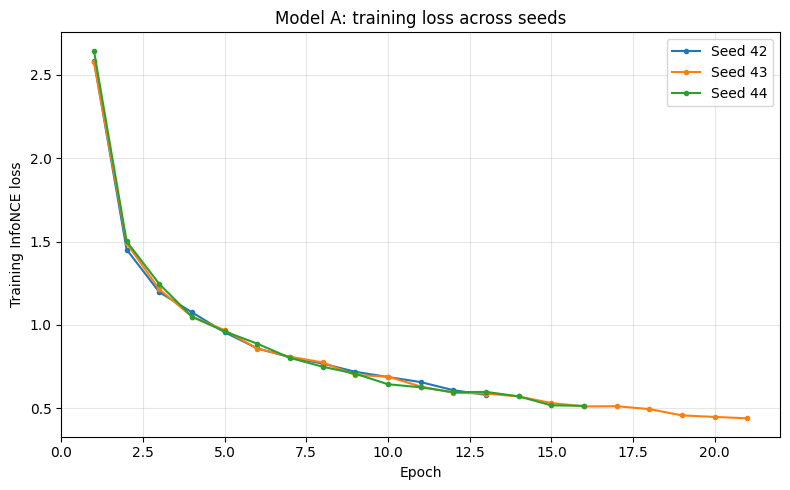

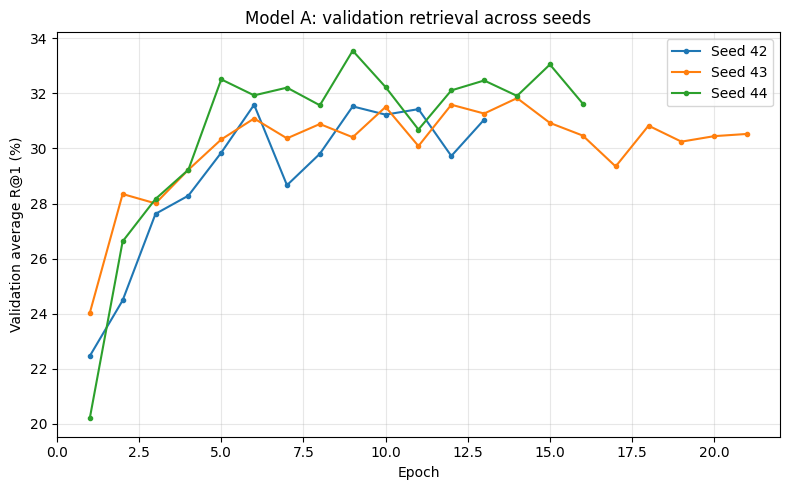

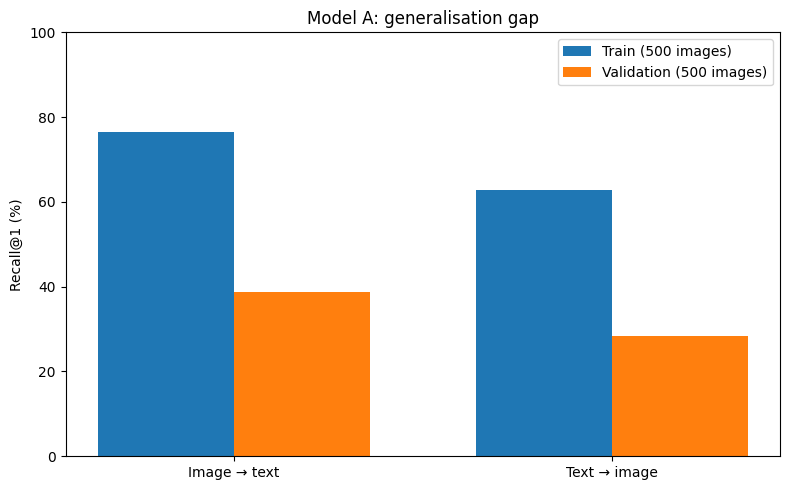

Saved three Model A figures to: /content/multimodal_project/results


In [11]:
# Training curves for all 3 seeds
fig, ax = plt.subplots(figsize=(8, 5))
for seed in RUN_SEEDS:
    with (RESULTS / f"infonce_history_seed_{seed}.json").open() as f:
        h = json.load(f)
    ax.plot([v["epoch"] for v in h], [v["train_loss"] for v in h], marker=".", label=f"Seed {seed}")
ax.set(xlabel="Epoch", ylabel="Training InfoNCE loss", title="Model A: training loss across seeds")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_training_loss.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for seed in RUN_SEEDS:
    with (RESULTS / f"infonce_history_seed_{seed}.json").open() as f:
        h = json.load(f)
    ax.plot([v["epoch"] for v in h], [v["val_average_r1"]*100 for v in h], marker=".", label=f"Seed {seed}")
ax.set(xlabel="Epoch", ylabel="Validation average R@1 (%)", title="Model A: validation retrieval across seeds")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_validation_recall.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Image → text", "Text → image"]
tr = [train_eval["ambiguous_aware"][d]["R@1"]*100 for d in ("image_to_text", "text_to_image")]
va = [val_eval["ambiguous_aware"][d]["R@1"]*100 for d in ("image_to_text", "text_to_image")]
x = np.arange(len(labels))
ax.bar(x - 0.18, tr, width=0.36, label="Train (500 images)")
ax.bar(x + 0.18, va, width=0.36, label="Validation (500 images)")
ax.set(xticks=x, xticklabels=labels, ylim=(0,100), ylabel="Recall@1 (%)", title="Model A: generalisation gap")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_overfitting.png", dpi=250)
plt.show()
print("Saved three Model A figures to:", RESULTS)

In [12]:
import torchvision, transformers, datasets
configuration = {
    "scope": "COCO preprocessing, frozen features, InfoNCE model",
    "dataset": DATASET, "dataset_split": DATA_SPLIT,
    "split_seed": SPLIT_SEED, "image_counts": [TRAIN_N, VAL_N, TEST_N],
    "seeds": RUN_SEEDS, "image_encoder": "ResNet50_Weights.DEFAULT",
    "text_encoder": "bert-base-uncased", "text_pooling": "masked_mean",
    "token_max_length": MAX_TOKENS,
    "image_dimensions": 2048, "text_dimensions": 768,
    "projection_dimensions": EMBED_DIM, "batch_size": BATCH_SIZE,
    "learning_rate": LR, "weight_decay": WEIGHT_DECAY,
    "InfoNCE_temperature": TEMP, "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "caption_sampling": "one caption per image per batch, random each epoch",
    "duplicate_handling": "mask identical caption negative pairs",
    "validation_rule": "duplicate-aware primary, strict-origin secondary",
    "best_seed": best_run["seed"], "best_epoch": best_run["best_epoch"],
    "python_version": platform.python_version(),
    "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
    "datasets_version": datasets.__version__, "transformers_version": transformers.__version__,
    "split_sha256": hashlib.sha256((DATA / "coco_splits.json").read_bytes()).hexdigest(),
    "test_untouched": True
}
with (MODELS / "infonce_config.json").open("w") as f:
    json.dump(configuration, f, indent=2)

model_zip = PROJECT / "InfoNCE_Model_A.zip"
model_files = ([MODELS / "infonce_best.pt", MODELS / "infonce_config.json"]
               + [MODELS / f"infonce_seed_{seed}_best.pt" for seed in RUN_SEEDS]
               + sorted(RESULTS.glob("infonce_*.json"))
               + sorted(RESULTS.glob("infonce_*.png")))
assert all(p.exists() for p in model_files)
with ZipFile(model_zip, "w", ZIP_DEFLATED) as z:
    for p in model_files:
        z.write(p, arcname=str(p.relative_to(PROJECT)))

print("Shared feature package:", shared_zip, "(", round(shared_zip.stat().st_size / 1024**2, 2), "MB)")
print("Model A package:", model_zip, "(", round(model_zip.stat().st_size / 1024**2, 2), "MB)")

Shared feature package: /content/multimodal_project/multimodal_shared_data.zip ( 116.34 MB)
Model A package: /content/multimodal_project/InfoNCE_Model_A.zip ( 10.52 MB)


## 3. Hard-negative triplet ranking

Keep the same projection architecture and data. Replace InfoNCE with bidirectional hardest-negative margin loss. Select margin using validation only.

In [13]:
import shutil
# Triplet loss: every diagonal image-caption pair is positive.
def hard_negative_loss(image_embeddings, text_embeddings, caption_indices, margin):
    similarity = image_embeddings @ text_embeddings.T
    diagonal = similarity.diag()
    n = len(diagonal)
    not_self = ~torch.eye(n, device=DEVICE, dtype=torch.bool)
    distinct_text = key_ids[caption_indices][:, None] != key_ids[caption_indices][None, :]
    legitimate_negative = not_self & distinct_text

    row_errors = (margin + similarity - diagonal[:, None]).clamp_min(0)
    col_errors = (margin + similarity - diagonal[None, :]).clamp_min(0)
    row_errors = row_errors.masked_fill(~legitimate_negative, 0)
    col_errors = col_errors.masked_fill(~legitimate_negative, 0)
    return 0.5 * (row_errors.amax(dim=1).mean() + col_errors.amax(dim=0).mean())


def train_triplet(seed, margin):
    torch.manual_seed(seed)
    random.seed(seed)
    sampler = random.Random(seed)
    network = InfoNCEModel().to(DEVICE)
    optimiser = torch.optim.AdamW(network.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    checkpoint_file = MODELS / f"triplet_margin{margin:.1f}_seed{seed}.pt"
    history, best, best_epoch, stalled = [], -1.0, 0, 0
    start = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        network.train()
        order = torch.randperm(TRAIN_N).tolist()
        batch_losses = []
        for start_index in range(0, TRAIN_N, BATCH_SIZE):
            indices = order[start_index:start_index+BATCH_SIZE]
            chosen = [sampler.choice(image_to_caption[i]) for i in indices]
            ix = torch.as_tensor(indices, device=DEVICE)
            tx = torch.as_tensor(chosen, device=DEVICE)
            a, b = network(X_img[ix], X_txt[tx])
            loss = hard_negative_loss(a, b, tx, margin)
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            batch_losses.append(loss.item())

        metrics = retrieval_metrics(network, val_ids, val_caption_ids)["ambiguous_aware"]
        score = 0.5*(metrics["image_to_text"]["R@1"] + metrics["text_to_image"]["R@1"])
        history.append({"epoch":epoch, "train_loss":float(np.mean(batch_losses)), "val_average_r1":score})
        if score > best + 1e-6:
            best, best_epoch, stalled = score, epoch, 0
            torch.save({"model_state_dict":network.state_dict(), "seed":seed,
                        "margin":margin, "best_epoch":epoch},checkpoint_file)
        else:
            stalled += 1
        if stalled >= PATIENCE:
            break

    history_path = RESULTS / f"triplet_margin{margin:.1f}_seed{seed}_history.json"
    history_path.write_text(json.dumps(history, indent=2))
    return {"seed":seed,"margin":margin,"best_epoch":best_epoch,
            "val_average_r1":best,"checkpoint":str(checkpoint_file),
            "elapsed_seconds":time.perf_counter()-start}


# A single fixed seed selects the margin; then evaluate the selected margin with 3 seeds.
triplet_margins = (0.1, 0.2, 0.3)
margin_trials = [train_triplet(RUN_SEEDS[0], m) for m in triplet_margins]
selected_margin = max(margin_trials, key=lambda r:r["val_average_r1"])["margin"]
triplet_runs = [next(r for r in margin_trials if r["margin"]==selected_margin)]
triplet_runs += [train_triplet(seed, selected_margin) for seed in RUN_SEEDS[1:]]
triplet_best = max(triplet_runs, key=lambda r:r["val_average_r1"])
shutil.copy2(triplet_best["checkpoint"], MODELS / "triplet_best.pt")
(RESULTS / "triplet_summary.json").write_text(json.dumps({
    "margin_trials":margin_trials,"selected_margin":selected_margin,"runs":triplet_runs,
    "selection":"validation mean image-to-text/text-to-image Recall@1"
},indent=2))
for r in triplet_runs:
    print(f"Triplet seed {r['seed']} | margin {r['margin']} | val avg R@1 {r['val_average_r1']:.2%}")

Triplet seed 42 | margin 0.2 | val avg R@1 31.61%
Triplet seed 43 | margin 0.2 | val avg R@1 32.03%
Triplet seed 44 | margin 0.2 | val avg R@1 30.05%


## 4. Early-fusion pair classifier

Project the two modalities, concatenate their representations, and learn compatibility with an MLP. Tune dropout using validation retrieval

In [14]:
class PairFusion(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.image_map = nn.Linear(2048, EMBED_DIM)
        self.text_map = nn.Linear(768, EMBED_DIM)
        self.predictor = nn.Sequential(
            nn.Linear(2 * EMBED_DIM, 256), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(256, 1)
        )

    def embed_images(self, x):
        return F.normalize(self.image_map(x), dim=-1)

    def embed_texts(self, x):
        return F.normalize(self.text_map(x), dim=-1)

    def score_embeddings(self, image_z, text_z):
        return self.predictor(torch.cat([image_z, text_z], dim=-1)).squeeze(-1)

    def forward(self, images, captions):
        return self.score_embeddings(self.embed_images(images), self.embed_texts(captions))


def fusion_score_matrix(network, image_subset, caption_subset, chunk=16384):
    network.eval()
    with torch.inference_mode():
        image_z = network.embed_images(X_img[image_subset])
        text_z = network.embed_texts(X_txt[caption_subset])
        n_images, n_captions = image_z.shape[0], text_z.shape[0]
        scores = torch.empty(n_images*n_captions, device=DEVICE)
        for start in range(0, scores.numel(), chunk):
            flat = torch.arange(start, min(start+chunk, scores.numel()), device=DEVICE)
            a = image_z[torch.div(flat, n_captions, rounding_mode='floor')]
            b = text_z[flat % n_captions]
            scores[start:start+len(flat)] = network.score_embeddings(a, b)
    return scores.reshape(n_images, n_captions)


def gallery_truth(image_subset, caption_subset):
    # Include equivalent captions shared across multiple images.
    image_list, caption_list = image_subset.tolist(), caption_subset.tolist()
    strict = image_subset[:,None].eq(caption_to_image[caption_subset][None,:])
    broad = strict.clone()
    columns_by_key = defaultdict(list)
    for col, cap_index in enumerate(caption_list):
        columns_by_key[caption_keys[cap_index]].append(col)
    for row, image_index in enumerate(image_list):
        for cap_index in image_to_caption[image_index]:
            for col in columns_by_key.get(caption_keys[cap_index],[]):
                broad[row,col] = True
    assert broad.any(dim=1).all() and broad.any(dim=0).all()
    return broad, strict

# Fixed galleries/masks are reused for training checkpoints and model comparison.
train_gallery = torch.randperm(TRAIN_N, generator=torch.Generator().manual_seed(SPLIT_SEED))[:500].to(DEVICE)
train_gallery_captions = torch.where(torch.isin(caption_to_image, train_gallery))[0]
test_ids = torch.arange(TRAIN_N+VAL_N, TRAIN_N+VAL_N+TEST_N, device=DEVICE)
test_caption_ids = torch.where(caption_to_image >= TRAIN_N+VAL_N)[0]
galleries = {
    "train": (train_gallery, train_gallery_captions),
    "validation": (val_ids, val_caption_ids),
    "test": (test_ids, test_caption_ids)
}
truth_masks = {name:gallery_truth(*pair) for name,pair in galleries.items()}


def assess_fusion(network, partition):
    image_idx, caption_idx = galleries[partition]
    scores = fusion_score_matrix(network, image_idx, caption_idx)
    positives = truth_masks[partition][0]
    return {"image_to_text":recall_mrr(scores, positives),
            "text_to_image":recall_mrr(scores.T, positives.T)}

print("Pairwise MLP parameters:",sum(p.numel() for p in PairFusion().parameters()))

Pairwise MLP parameters: 852993


In [15]:
# Each image contributes one positive caption and sampled negatives in both directions.
def train_fusion(seed, dropout):
    random.seed(seed)
    torch.manual_seed(seed)
    sample = random.Random(seed)
    network = PairFusion(dropout).to(DEVICE)
    opt = torch.optim.AdamW(network.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    path = MODELS / f"fusion_dropout{dropout:.1f}_seed{seed}.pt"
    best, best_epoch, bad_epochs, log = -1.0, 0, 0, []
    start = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS+1):
        network.train()
        order = torch.randperm(TRAIN_N).tolist()
        batch_losses = []
        for offset in range(0, TRAIN_N, BATCH_SIZE):
            chosen_images = order[offset:offset+BATCH_SIZE]
            chosen_texts = [sample.choice(image_to_caption[idx]) for idx in chosen_images]
            image_idx = torch.as_tensor(chosen_images,device=DEVICE)
            text_idx = torch.as_tensor(chosen_texts,device=DEVICE)
            positive = network(X_img[image_idx], X_txt[text_idx])
            pos_loss = F.softplus(-positive).mean()

            neg_img, neg_txt, allowed = [], [], []
            if len(chosen_images)>1:
                for _ in range(4):
                    distance = sample.randrange(1,len(chosen_images))
                    rotated_imgs = image_idx.roll(distance)
                    rotated_txts = text_idx.roll(distance)
                    neg_img.extend((image_idx,rotated_imgs))
                    neg_txt.extend((rotated_txts,text_idx))
                    distinct = key_ids[text_idx] != key_ids[rotated_txts]
                    allowed.extend((distinct,distinct))
                neg_img_idx = torch.cat(neg_img)
                neg_txt_idx = torch.cat(neg_txt)
                valid = torch.cat(allowed)
                wrong_scores = network(X_img[neg_img_idx],X_txt[neg_txt_idx])
                neg_loss = F.softplus(wrong_scores[valid]).mean() if valid.any() else wrong_scores.sum()*0
            else:
                neg_loss = positive.sum()*0
            loss = (pos_loss + neg_loss)/2
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())

        metrics = assess_fusion(network,"validation")
        score = 0.5*(metrics["image_to_text"]["R@1"] + metrics["text_to_image"]["R@1"])
        log.append({"epoch":epoch,"train_loss":float(np.mean(batch_losses)),"val_average_r1":score})
        if score>best+1e-6:
            best, best_epoch, bad_epochs = score, epoch, 0
            torch.save({"model_state_dict":network.state_dict(),"dropout":dropout,
                        "seed":seed,"best_epoch":epoch},path)
        else:
            bad_epochs += 1
        if bad_epochs>=PATIENCE:
            break
    (RESULTS / f"fusion_dropout{dropout:.1f}_seed{seed}_history.json").write_text(json.dumps(log,indent=2))
    return {"seed":seed,"dropout":dropout,"best_epoch":best_epoch,
            "val_average_r1":best,"checkpoint":str(path),
            "elapsed_seconds":time.perf_counter()-start}

fusion_dropout_grid = (0.0, 0.2)
fusion_trials = [train_fusion(seed, dropout) for dropout in fusion_dropout_grid for seed in RUN_SEEDS]
fusion_choice = max(fusion_dropout_grid,
                    key=lambda d:np.mean([r["val_average_r1"] for r in fusion_trials if r["dropout"]==d]))
fusion_runs = [r for r in fusion_trials if r["dropout"] == fusion_choice]
fusion_best = max(fusion_runs,key=lambda r:r["val_average_r1"])
shutil.copy2(fusion_best["checkpoint"],MODELS/"fusion_best.pt")
(RESULTS/"fusion_summary.json").write_text(json.dumps({
    "dropout_grid":fusion_dropout_grid,"selected_dropout":fusion_choice,
    "runs":fusion_trials,"selection":"validation mean Recall@1 over three seeds"
},indent=2))
for r in fusion_runs:
    print(f"Early fusion seed {r['seed']} | dropout {r['dropout']} | val avg R@1 {r['val_average_r1']:.2%}")

Early fusion seed 42 | dropout 0.0 | val avg R@1 5.90%
Early fusion seed 43 | dropout 0.0 | val avg R@1 5.64%
Early fusion seed 44 | dropout 0.0 | val avg R@1 5.32%


## 5. Generalisation and held-out test comparison

Select configurations on validation only, then report the final test metrics for both retrieval directions.

In [16]:
def read_projection(path):
    ck = torch.load(path,map_location=DEVICE,weights_only=True)
    model = InfoNCEModel().to(DEVICE)
    model.load_state_dict(ck["model_state_dict"])
    model.eval()
    return model


def read_fusion(path):
    ck = torch.load(path,map_location=DEVICE,weights_only=True)
    model = PairFusion(ck["dropout"]).to(DEVICE)
    model.load_state_dict(ck["model_state_dict"])
    model.eval()
    return model


def assess_projection(model, partition):
    ix, tx = galleries[partition]
    with torch.inference_mode():
        a = F.normalize(model.image_projection(X_img[ix]),dim=-1)
        b = F.normalize(model.text_projection(X_txt[tx]),dim=-1)
        scores = a @ b.T
    truth = truth_masks[partition][0]
    return {"image_to_text":recall_mrr(scores,truth),
            "text_to_image":recall_mrr(scores.T,truth.T)}


selected_runs = {"InfoNCE":run_summaries,"Triplet":triplet_runs,"Early Fusion":fusion_runs}
loader = {"InfoNCE":read_projection,"Triplet":read_projection,"Early Fusion":read_fusion}
evaluator = {"InfoNCE":assess_projection,"Triplet":assess_projection,"Early Fusion":assess_fusion}

# Analysis uses the validation-selected best seed of each architecture.
generalisation = {}
for name,runs in selected_runs.items():
    top = max(runs,key=lambda r:r["best_val_average_r1"] if "best_val_average_r1" in r else r["val_average_r1"])
    selected_model = loader[name](top["checkpoint"])
    training = evaluator[name](selected_model,"train")
    validation = evaluator[name](selected_model,"validation")
    generalisation[name] = {"selected_seed":top["seed"],"train":training,"validation":validation}
    print(name, "train / val average R@1:",
          f"{np.mean([training[d]['R@1'] for d in training]):.2%}","/",
          f"{np.mean([validation[d]['R@1'] for d in validation]):.2%}")

# Held-out test, evaluated only after all configuration/seed selection is complete.
final_test = {}
for name,runs in selected_runs.items():
    per_seed=[]
    for run in runs:
        trained = loader[name](run["checkpoint"])
        metrics = evaluator[name](trained,"test")
        per_seed.append({"seed":run["seed"],"metrics":metrics})
    final_test[name] = per_seed

summary={}
for name,runs in final_test.items():
    summary[name]={}
    for direction in ("image_to_text","text_to_image"):
        summary[name][direction]={}
        for metric in ("R@1","R@5","R@10","MRR"):
            values=[r["metrics"][direction][metric] for r in runs]
            summary[name][direction][metric]={"mean":float(np.mean(values)),
                "sd":float(np.std(values,ddof=1)) if len(values)>1 else 0.0}

(RESULTS/"individual_comparison.json").write_text(json.dumps({
    "split_hash":hashlib.sha256((DATA/"coco_splits.json").read_bytes()).hexdigest(),
    "margin":selected_margin,"dropout":fusion_choice,
    "train_validation":generalisation,"test_runs":final_test,"test_summary":summary
},indent=2))

print("\nHELD-OUT TEST: average Recall@1 across three seeds")
for name,values in summary.items():
    print(name,"I2T",f"{values['image_to_text']['R@1']['mean']:.2%}",
          "T2I",f"{values['text_to_image']['R@1']['mean']:.2%}")

InfoNCE train / val average R@1: 69.74% / 33.55%
Triplet train / val average R@1: 62.40% / 32.03%
Early Fusion train / val average R@1: 6.22% / 5.90%

HELD-OUT TEST: average Recall@1 across three seeds
InfoNCE I2T 38.27% T2I 30.32%
Triplet I2T 37.07% T2I 29.79%
Early Fusion I2T 5.07% T2I 4.53%


## 6. Results and export

Save the cross-model figures, retrieval examples, and a portable results archive.

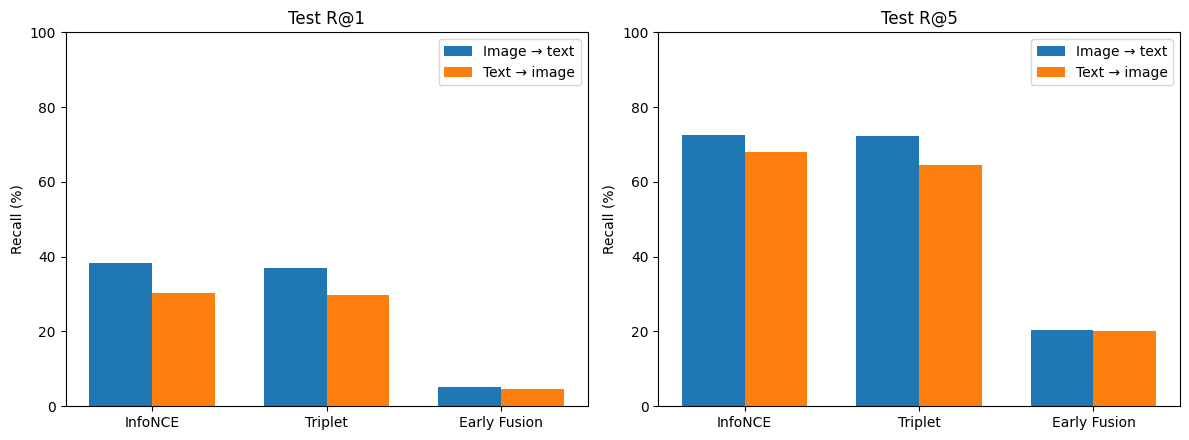

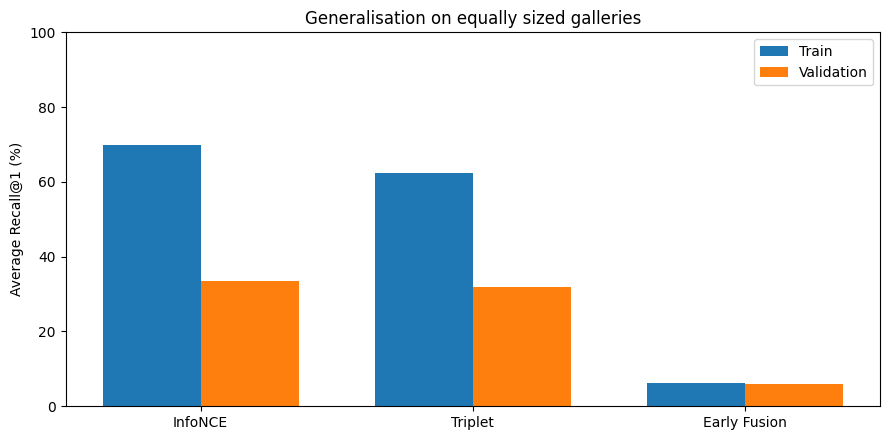

Saved results: /content/multimodal_project/results
Archive: /content/multimodal_project/Individual_Retrieval_Results.zip


In [17]:
# Compact comparison figure: R@1 and R@5 in both directions.
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax, metric in zip(axes,("R@1","R@5")):
    x=np.arange(3)
    for offset,direction,title in [(-.18,"image_to_text","Image → text"),(.18,"text_to_image","Text → image")]:
        values=[summary[m][direction][metric]["mean"]*100 for m in selected_runs]
        ax.bar(x+offset,values,width=.36,label=title)
    ax.set(xticks=x,xticklabels=list(selected_runs),ylabel="Recall (%)",title=f"Test {metric}",ylim=(0,100))
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS/"retrieval_test_comparison.png",dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(9,4.5))
x=np.arange(3)
for offset,partition in [(-.18,"train"),(.18,"validation")]:
    values=[100*np.mean([generalisation[name][partition][d]["R@1"] for d in ("image_to_text","text_to_image")]) for name in selected_runs]
    ax.bar(x+offset, values,width=.36,label=partition.title())
ax.set(xticks=x,xticklabels=list(selected_runs),ylabel="Average Recall@1 (%)",title="Generalisation on equally sized galleries",ylim=(0,100))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS/"retrieval_generalisation.png",dpi=250)
plt.show()

# Qualitative inspection: image-to-text failures for each validation-selected model.
image_idx, caption_idx = galleries["test"]
examples={}
for name,runs in selected_runs.items():
    best_run_for_model=max(runs,key=lambda r:r["best_val_average_r1"] if "best_val_average_r1" in r else r["val_average_r1"])
    model=loader[name](best_run_for_model["checkpoint"])
    if name=="Early Fusion":
        scores=fusion_score_matrix(model,image_idx,caption_idx)
    else:
        with torch.inference_mode():
            scores=F.normalize(model.image_projection(X_img[image_idx]),dim=-1) @ F.normalize(model.text_projection(X_txt[caption_idx]),dim=-1).T
    truth=truth_masks["test"][0]
    top=scores.argmax(dim=1)
    mistakes=[]
    for row in range(len(image_idx)):
        if not truth[row,top[row]]:
            img_id=image_idx[row].item()
            cap_id=caption_idx[top[row]].item()
            mistakes.append({"image_id":image_ids[img_id],
                "retrieved_caption":texts["captions"][cap_id],
                "reference_captions":all_records[img_id]["captions"][:3]})
        if len(mistakes)==5:
            break
    examples[name]=mistakes
(RESULTS/"retrieval_failure_examples.json").write_text(json.dumps(examples,indent=2,ensure_ascii=False))

# Include both the code-produced model checkpoints and result summaries.
archive=PROJECT/"Individual_Retrieval_Results.zip"
with ZipFile(archive,"w",ZIP_DEFLATED) as z:
    for folder in (MODELS,RESULTS):
        for path in sorted(folder.iterdir()):
            if path.is_file():
                z.write(path,arcname=str(path.relative_to(PROJECT)))
print("Saved results:",RESULTS)
print("Archive:",archive)